# M2 · Latent re-parameterization and the latent-size sweep

**Goal of M2:** make the M1 detector *latent*. M1 trains P = 104,450 numbers (all 50 LayerNorms + the linear head). M2 generates them instead:

**θ = θ0 + α · W z**

- θ0: the starting values (CLIP's LayerNorms + the head's initial values), frozen
- W: a P × d random matrix, regenerated from a seed (`W_SEED`) whenever it is needed and never stored
- z ∈ R^d and the scalar α: the only trained numbers (d + 1)

We train the M1 recipe for d = 16 … 4096 and measure how much seen and unseen (FaceShifter) AUC survives compared with full LN tuning.

**Why GBLA needs this.** GBLA lives in this latent space (a shared z_s plus per-generator z_g). M2 answers three questions first: (1) is a small latent (ideally d = 64) expressive enough; (2) what the deployed model costs (d + 1 numbers + a seed); (3) it produces the pooled latent solution at d = 64 that E1 (M3) analyses.

**Borrowed vs ours.** Training in a random subspace is the *intrinsic dimension* method (Li et al., ICLR 2018; Aghajanyan et al., ACL 2021 for fine-tuning). Generating the basis from a seed instead of storing it follows PRANC (Nooralinejad et al., ICCV 2023) and NOLA (Koohpayegani et al., ICLR 2024). New in M2 is only applying it to the LN-tuned CLIP detector and measuring unseen-generator AUC as a function of d.

**Design choices**

| choice | why |
|---|---|
| W entries drawn from N(0, 1/d) | one Adam step on z then moves each of the P parameters by roughly the learning rate, whatever d is, so one learning rate fits all d |
| z = 0 and α = 1 at the start | training starts exactly at M1's starting point |
| learning rate picked once at d = 64 (4.2) | the right step size for z is not known from M1; a short probe picks it from a grid by training loss |
| 10 epochs (one learning-rate cycle) per d | in M1, FaceShifter AUC at epoch 7 equalled epoch 20 and FF++ val saturated by epoch 6; M1 is also scored at epoch 10 for a matched comparison |
| data, loss, augmentation, batch, schedule shape as in M1 | only the parameterization changes |

**From M1** (video AUC %, final epoch; paper LNCLIP-DF in brackets): FF 98.04 (98.0) · DF 99.39 (99.6) · F2F 98.40 (98.2) · FS 99.38 (98.6) · NT 94.98 (95.7) · **FaceShifter, unseen: 88.37 (88.2)**. The reproduction holds. Two corrections from M1:

- `frames_all` is **not** scrambled. It is flat (`<category>/<video>_frame_NN.jpg`). M0 2.2 listed frames without filtering by video, which mixed videos *in that display only*; extraction filtered correctly, and M1's pairing test (99–100%) confirms the crops.
- M1 took 18 min per epoch, not 8. Data loading (~125 img/s) was the bottleneck, not the GPU (253 img/s); the speed test was fooled by batches already waiting in the queue, and the job may use only 8 of the node's 256 CPUs. M2 keeps the decoded crops in RAM, uses as many loader workers as usable CPUs, monitors val on 8 frames per video, and measures loading speed properly (2.4).

| Section | What it does | Run time |
|---|---|---|
| 1. Setup | settings, imports, usable CPUs and RAM | seconds |
| 2. Data | index, crops into RAM, loaders, loading-speed test | 5–25 min per session (disk speed) |
| 3. Model | latent detector, correctness checks, parameter report | ~2 min |
| 4. Training | learning-rate probe (once), then the d sweep (resumable) | probe ~15 min; ~1.5–3 h per d |
| 5. Evaluation | M1 reference, AUC vs d, curves | ~5 min |
| 6. Send results back | push this notebook | – |

## 1. Setup

### 1.1 Settings

`DATA_ROOT` is the same folder as in M0 and M1. Every d gets its own run folder under `runs/m2/`. Settings that change results are stored in each run's `config.json`; 4.3 refuses to continue a run whose settings changed. `D_LIST` is in priority order: if time runs out, the first values are the important ones.

In [1]:
# 1.1 Settings
import os
from pathlib import Path

DATA_ROOT = Path("/nlsasfs/home/isea/isea64/GBLA-Deepfake Detection")   # same as M0 / M1
FACES_ROOT = DATA_ROOT / "faces"
INDEX_CSV = DATA_ROOT / "index" / "ffpp_c23.csv"
RUNS_ROOT = DATA_ROOT / "runs"
M2_DIR = RUNS_ROOT / "m2"

# protocol (same as M1)
ALL_GENERATORS = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures", "FaceShifter"]
TRAIN_GENERATORS = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures"]   # FaceShifter = unseen
SHORT = {"original": "real", "Deepfakes": "DF", "Face2Face": "F2F", "FaceSwap": "FS",
         "NeuralTextures": "NT", "FaceShifter": "FSh"}

# model, loss, optimisation (same as M1)
ARCH, PRETRAINED = "ViT-L-14", "openai"
L2_NORM = True
W_UNIFORM, W_ALIGN = 0.5, 0.1
AUGMENT = True
BATCH_SIZE = 128
CYCLE_EPOCHS = 10
WARMUP_EPOCHS = 1
SEED = 0

# M2: latent re-parameterization  theta = theta0 + alpha * W z
D_LIST = [64, 256, 1024, 16, 4096]   # run order = priority; GBLA's default is d = 64
EPOCHS = 10                           # one learning-rate cycle per d
W_SEED = 2026                         # the seed is all that is needed to rebuild W
LR_GRID = [3e-4, 1e-3, 3e-3, 1e-2, 3e-2]   # peak learning rates tried by the probe (4.2)
PROBE_D, PROBE_STEPS, PROBE_BATCHES = 64, 240, 60
LR_RATIO = 30                         # LR_MIN = LR_MAX / 30, as in M1 (3e-4 / 1e-5)

# the M1 run = full LN tuning reference
M1_RUN_DIR = RUNS_ROOT / "m1" / f"lnclip_{ARCH}_train-{'-'.join(SHORT[g] for g in TRAIN_GENERATORS)}_seed{SEED}"

# speed only (do not change the trained models)
VAL_FRAMES_PER_VIDEO = 8      # val is only monitored; test always uses all 32 frames
CACHE_IN_RAM = True           # keep decoded crops in RAM if there is enough memory (2.2)
EVAL_BATCH = 256
GRAD_CHECKPOINTING = False

COMMON_CONFIG = {
    "arch": ARCH, "pretrained": PRETRAINED, "quick_gelu": True,
    "train_generators": TRAIN_GENERATORS, "l2_norm": L2_NORM,
    "w_uniform": W_UNIFORM, "w_align": W_ALIGN, "augment": AUGMENT,
    "batch_size": BATCH_SIZE, "epochs": EPOCHS, "cycle_epochs": CYCLE_EPOCHS,
    "warmup_epochs": WARMUP_EPOCHS, "seed": SEED,
    "w_seed": W_SEED, "w_entries": "N(0, 1/d)", "z_init": 0.0, "alpha_init": 1.0,
}
assert INDEX_CSV.exists(), f"index not found: {INDEX_CSV} (run M0 first)"
assert (M1_RUN_DIR / "last.pt").exists(), f"M1 run not found: {M1_RUN_DIR}"
M2_DIR.mkdir(parents=True, exist_ok=True)
print("M2 runs go to:", M2_DIR)

M2 runs go to: /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m2


### 1.2 Imports and environment

`os.cpu_count()` reports the whole node (256), but the job may only use the CPUs in its affinity mask and cgroup quota; the loader uses that number. Free RAM decides in 2.2 how many crops can be kept in memory.

In [2]:
# 1.2 Imports and environment
import json, math, random, time
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
from torch.utils.data import DataLoader, Dataset, Sampler
from torchvision import tv_tensors
from torchvision.io import ImageReadMode, read_image
from torchvision.transforms import v2 as T
from tqdm.auto import tqdm

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
assert torch.cuda.is_available(), "M2 needs the GPU"
DEVICE = "cuda"


def usable_cpus():
    """CPUs this job may use: the affinity mask and the cgroup CPU quota."""
    n = len(os.sched_getaffinity(0))
    for quota_file, period_file in [("/sys/fs/cgroup/cpu.max", None),
                                    ("/sys/fs/cgroup/cpu/cpu.cfs_quota_us", "/sys/fs/cgroup/cpu/cpu.cfs_period_us")]:
        try:
            if period_file is None:
                quota, period = Path(quota_file).read_text().split()
            else:
                quota, period = Path(quota_file).read_text().strip(), Path(period_file).read_text().strip()
            if quota not in ("max", "-1"):
                n = min(n, max(1, int(quota) // int(period)))
        except (OSError, ValueError):
            pass
    return n


def available_memory_gb():
    """Free RAM for this job: the smaller of MemAvailable and the cgroup limit minus non-cache usage."""
    candidates = []
    try:
        meminfo = dict(line.split(":", 1) for line in Path("/proc/meminfo").read_text().splitlines())
        candidates.append(int(meminfo["MemAvailable"].split()[0]) * 1024)
    except (OSError, KeyError, ValueError):
        pass
    for limit_file, usage_file, stat_file, cache_key in [
            ("/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory.current", "/sys/fs/cgroup/memory.stat", "file"),
            ("/sys/fs/cgroup/memory/memory.limit_in_bytes", "/sys/fs/cgroup/memory/memory.usage_in_bytes",
             "/sys/fs/cgroup/memory/memory.stat", "cache")]:
        try:
            limit = Path(limit_file).read_text().strip()
            if not limit.isdigit() or int(limit) >= 1 << 60:
                continue
            usage = int(Path(usage_file).read_text().strip())
            stat = dict(line.split() for line in Path(stat_file).read_text().splitlines())
            candidates.append(int(limit) - usage + int(stat.get(cache_key, 0)))
        except (OSError, ValueError):
            pass
    return min(candidates) / 1e9 if candidates else 0.0


CPUS = usable_cpus()
NUM_WORKERS = max(1, min(16, CPUS - 1))     # one CPU stays with the training process
torch.set_num_threads(2)

pd.Series({
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "open_clip": open_clip.__version__,
    "GPU": torch.cuda.get_device_name(0),
    "CPU cores on the node": os.cpu_count(),
    "CPUs usable by this job": CPUS,
    "data loader workers": NUM_WORKERS,
    "free RAM for this job (GB)": round(available_memory_gb(), 1),
}, name="value").to_frame()

/nlsasfs/home/isea/isea64/venv_jupyter/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,value
torch,2.6.0+cu124
torchvision,0.21.0+cu124
open_clip,3.3.0
GPU,NVIDIA A100-SXM4-40GB
CPU cores on the node,256
CPUs usable by this job,8
data loader workers,7
free RAM for this job (GB),1059.0


## 2. Data

### 2.1 Index and subsets

Same splits as M1: train = real + the 4 training generators (115,200 crops); test = real + all 5 generators, FaceShifter unseen. Val keeps 8 evenly spaced frames of each video (5,600 crops instead of 22,400). Val only monitors training, so this changes no trained model; val numbers are therefore not identical to M1's.

In [3]:
# 2.1 Index and subsets
index = pd.read_csv(INDEX_CSV, dtype={"video_id": str, "target_id": str, "source_id": str},
                    keep_default_na=False)
CATEGORIES = ["original"] + ALL_GENERATORS
GEN_CODE = {g: k for k, g in enumerate(CATEGORIES)}


def subset(split, generators):
    keep = (index.split == split) & index.generator.isin(["original", *generators])
    return index[keep].reset_index(drop=True)


train_df = subset("train", TRAIN_GENERATORS)
val_all = subset("val", TRAIN_GENERATORS)
frames_per_video = int(val_all.groupby(["generator", "video_id"]).size().max())
keep_every = max(1, frames_per_video // VAL_FRAMES_PER_VIDEO)
frame_rank = val_all.groupby(["generator", "video_id"]).frame_idx.rank(method="first").astype(int) - 1
val_df = val_all[frame_rank % keep_every == 0].reset_index(drop=True)
test_df = subset("test", ALL_GENERATORS)

display(pd.DataFrame({name: df.groupby("generator").size().reindex(CATEGORIES)
                      for name, df in [("train", train_df), ("val (subsampled)", val_df), ("test", test_df)]}
                     ).fillna(0).astype(int))

,train,val (subsampled),test
generator,,,
original,23040,1120,4480
Deepfakes,23040,1120,4480
Face2Face,23040,1120,4480
FaceSwap,23040,1120,4480
NeuralTextures,23040,1120,4480
FaceShifter,0,0,4480


### 2.2 Decoded crops in RAM

Reading 115,200 small PNG files per epoch from the network file system was the likely M1 bottleneck. Here every crop is read once per session into one uint8 array (224 × 224 × 3 bytes per crop: train 17.3 GB, val 0.8 GB, test 4.0 GB), in the order train → val → test, as long as it fits in 60% of free RAM. Sets that don't fit are read from disk as in M1. Nothing is written to disk. The printed read speed also tells us how fast the file system is.

In [4]:
# 2.2 Decoded crops in RAM
def load_images(df, desc):
    """Decodes every crop of an index slice into one uint8 array (N, H, W, 3), using threads."""
    paths = [FACES_ROOT / p for p in df.path]
    first = np.asarray(Image.open(paths[0]).convert("RGB"))
    out = np.empty((len(paths), *first.shape), dtype=np.uint8)

    def work(k):
        out[k] = np.asarray(Image.open(paths[k]).convert("RGB"))

    with ThreadPoolExecutor(max_workers=min(32, 4 * CPUS)) as pool:
        list(tqdm(pool.map(work, range(len(paths))), total=len(paths), desc=desc, mininterval=5))
    return out


images = {}
budget = 0.6 * available_memory_gb()
for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    need = len(df) * 224 * 224 * 3 / 1e9
    if CACHE_IN_RAM and need <= budget:
        t = time.time()
        images[name] = load_images(df, f"{name} crops -> RAM")
        budget -= need
        sec = time.time() - t
        print(f"{name}: {len(df):,} crops, {need:.1f} GB in RAM, {sec / 60:.1f} min ({len(df) / sec:.0f} crops/s from disk)")
    else:
        images[name] = None
        print(f"{name}: read from disk during training (needs {need:.1f} GB, RAM budget left {budget:.1f} GB)")

train crops -> RAM: 100%|██████████| 115200/115200 [01:12<00:00, 1585.20it/s]


train: 115,200 crops, 17.3 GB in RAM, 1.3 min (1519 crops/s from disk)


val crops -> RAM: 100%|██████████| 5600/5600 [00:03<00:00, 1677.93it/s]


val: 5,600 crops, 0.8 GB in RAM, 0.1 min (1626 crops/s from disk)


test crops -> RAM: 100%|██████████| 26880/26880 [00:16<00:00, 1633.37it/s]

test: 26,880 crops, 4.0 GB in RAM, 0.3 min (1578 crops/s from disk)


### 2.3 Datasets and loaders

Same transforms, augmentations and seeded epoch order as M1. A dataset reads from the RAM array when there is one, otherwise from disk.

In [5]:
# 2.3 Datasets and loaders
CLIP_MEAN = (0.48145466, 0.4578275, 0.40821073)
CLIP_STD = (0.26862954, 0.26130258, 0.27577711)


def make_transform(train):
    steps = []
    if train and AUGMENT:
        steps += [
            T.RandomHorizontalFlip(0.5),
            T.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
            T.RandomApply([T.GaussianBlur(kernel_size=7, sigma=(0.1, 2.0))], p=0.1),
            T.ColorJitter(brightness=0.1, contrast=0.1),
            T.JPEG(quality=(40, 100)),
        ]
    steps += [T.ToDtype(torch.float32, scale=True), T.Normalize(CLIP_MEAN, CLIP_STD)]
    return T.Compose(steps)


class FaceDataset(Dataset):
    """Returns (image, label, generator code) for every row of an index slice."""

    def __init__(self, df, train, images=None):
        self.paths = [str(FACES_ROOT / p) for p in df.path]
        self.images = images
        self.labels = torch.tensor(df.label.values, dtype=torch.long)
        self.gens = torch.tensor(df.generator.map(GEN_CODE).values, dtype=torch.long)
        self.transform = make_transform(train)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        if self.images is not None:
            image = torch.from_numpy(np.array(self.images[i])).permute(2, 0, 1)
        else:
            image = read_image(self.paths[i], mode=ImageReadMode.RGB)
        return self.transform(tv_tensors.Image(image)).as_subclass(torch.Tensor), self.labels[i], self.gens[i]


class EpochSampler(Sampler):
    """Random order that depends only on (seed, epoch), so resumed runs see the same order."""

    def __init__(self, n, seed):
        self.n, self.seed, self.epoch = n, seed, 0

    def set_epoch(self, epoch):
        self.epoch = epoch

    def __iter__(self):
        g = torch.Generator().manual_seed(self.seed * 100_003 + self.epoch)
        return iter(torch.randperm(self.n, generator=g).tolist())

    def __len__(self):
        return self.n


train_ds = FaceDataset(train_df, train=True, images=images["train"])
train_sampler = EpochSampler(len(train_ds), SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=train_sampler, drop_last=True,
                          num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True, prefetch_factor=4)
print(f"steps per epoch: {len(train_loader)}, loader workers: {NUM_WORKERS}")

steps per epoch: 900, loader workers: 7


### 2.4 Data-loading speed

Measured properly this time: the batches the workers prepared in advance are taken out first, then 30 batches are timed. Also measured: the CPU time to prepare one augmented crop in a single process. If loading is slower than the GPU (M1: 253 img/s), the table says so; send me the output and I'll move the augmentations to the GPU.

In [6]:
# 2.4 Data-loading speed
def loader_rate(loader, n_batches=30):
    """Steady-state images/s after the pre-fetched batches are used up."""
    it = iter(loader)
    for _ in range(NUM_WORKERS * 4 + 2):
        next(it)
    t = time.time()
    for _ in range(n_batches):
        next(it)
    rate = n_batches * loader.batch_size / (time.time() - t)
    del it
    return rate


t = time.time()
for i in range(200):
    train_ds[i]
ms_per_crop = (time.time() - t) / 200 * 1000
load_speed = loader_rate(train_loader)
GPU_SPEED_M1 = 253
speed = min(load_speed, GPU_SPEED_M1)
pd.Series({
    "CPU time per augmented crop, one process (ms)": round(ms_per_crop, 1),
    "data loading speed (img/s)": round(load_speed),
    "GPU training speed in M1 (img/s)": GPU_SPEED_M1,
    "bottleneck": "GPU" if load_speed >= GPU_SPEED_M1 else "data loading",
    "estimated minutes per epoch (training part)": round(len(train_loader) * BATCH_SIZE / speed / 60, 1),
    f"estimated hours per d ({EPOCHS} epochs)": round(EPOCHS * len(train_loader) * BATCH_SIZE / speed / 3600, 1),
}, name="value").to_frame()

,value
"CPU time per augmented crop, one process (ms)",18.0
data loading speed (img/s),926
GPU training speed in M1 (img/s),253
bottleneck,GPU
estimated minutes per epoch (training part),7.6
estimated hours per d (10 epochs),1.3


## 3. Model

### 3.1 Detector with generated LayerNorm and head parameters

Same detector as M1 (CLIP ViT-L/14, QuickGELU, 1024-d CLS token, L2-normalized, linear head; same head initialisation from `SEED`). Then the 100 adapted tensors (50 LayerNorms × scale and shift, the head's weight and bias) stop being parameters: their starting values are flattened into θ0 (P numbers, fixed order), and before every forward pass `write_theta` puts the current θ back into the modules. Gradients flow from the loss through θ to z and α.

Check: with θ = θ0 the logits on 4 val crops (2 real, 2 fake) must equal those of the ordinary model.

In [7]:
# 3.1 Detector with generated LayerNorm and head parameters
class Detector(nn.Module):
    def __init__(self):
        super().__init__()
        encoder = open_clip.create_model(ARCH, pretrained=PRETRAINED, force_quick_gelu=True).visual
        encoder.proj = None                      # keep the 1024-d CLS token
        self.encoder = encoder
        self.head = nn.Linear(encoder.transformer.width, 2)

    def forward(self, x):
        """Returns (logits, L2-normalized features)."""
        feats = self.encoder(x).float()
        f = F.normalize(feats, dim=-1)
        return self.head(f if L2_NORM else feats), f


torch.manual_seed(SEED)
model = Detector().to(DEVICE)
model.requires_grad_(False)
model.encoder.set_grad_checkpointing(GRAD_CHECKPOINTING)

# the adapted tensors, in a fixed order: every LayerNorm (scale, shift), then the head (weight, bias)
TARGETS = [(name, module, attr) for name, module in model.named_modules()
           if isinstance(module, nn.LayerNorm) or module is model.head
           for attr in ("weight", "bias")]
TARGET_NAMES = [f"{name}.{attr}" for name, _, attr in TARGETS]
TARGET_SHAPES = [tuple(getattr(m, a).shape) for _, m, a in TARGETS]
THETA0 = torch.cat([getattr(m, a).detach().reshape(-1) for _, m, a in TARGETS]).float()
P = THETA0.numel()

check_ds = FaceDataset(pd.concat([val_df[val_df.label == 0].iloc[:2], val_df[val_df.label == 1].iloc[:2]]), train=False)
check_x = torch.stack([check_ds[k][0] for k in range(4)]).to(DEVICE)
check_y = check_ds.labels.to(DEVICE)
with torch.no_grad():
    ref_logits, _ = model(check_x)

for _, m, a in TARGETS:
    delattr(m, a)


def write_theta(theta):
    """Puts the flat vector theta (length P) into the LayerNorms and the head."""
    offset = 0
    for (_, m, a), shape in zip(TARGETS, TARGET_SHAPES):
        n = math.prod(shape)
        setattr(m, a, theta[offset:offset + n].view(shape))
        offset += n


with torch.no_grad():
    write_theta(THETA0)
    new_logits, _ = model(check_x)
diff = (new_logits - ref_logits).abs().max().item()
print(f"adapted tensors: {len(TARGETS)}, P = {P:,}")
print(f"max logit difference, generated vs ordinary parameters: {diff:.2e}")
assert diff < 1e-4, "write_theta does not reproduce the model"
if ARCH == "ViT-L-14":
    assert P == 104_450

adapted tensors: 102, P = 104,450
max logit difference, generated vs ordinary parameters: 0.00e+00


### 3.2 Latent adapter

`LatentAdapter(d)` holds z (d numbers, starts at 0), α (1 number, starts at 1) and W (P × d, entries N(0, 1/d), built on the GPU from `W_SEED`, never saved; 0.4 GB at d = 1024, 1.7 GB at d = 4096). The **fingerprint** of W is stored in each run's config: if a later session (e.g. after a library update) regenerated a different W, resuming is refused instead of silently continuing with a different model.

A trained model is fully described by its *payload*: the d numbers of z, α, and the seeds. 4.3 writes it to `payload.json` in each run folder.

In [8]:
# 3.2 Latent adapter
def random_basis(d, seed):
    """W: P x d, entries N(0, 1/d). Regenerated from the seed on the GPU, never stored."""
    g = torch.Generator(device=DEVICE).manual_seed(seed)
    return torch.randn(P, d, generator=g, device=DEVICE) / math.sqrt(d)


def w_fingerprint(W):
    return [round(W.double().sum().item(), 6), round(W[0, 0].item(), 8), round(W[-1, -1].item(), 8)]


class LatentAdapter(nn.Module):
    """theta = THETA0 + alpha * W z; trainable: z (d numbers) and alpha (1 number)."""

    def __init__(self, d, seed=W_SEED):
        super().__init__()
        self.d, self.seed = d, seed
        self.z = nn.Parameter(torch.zeros(d, device=DEVICE))
        self.alpha = nn.Parameter(torch.ones((), device=DEVICE))
        self.register_buffer("W", random_basis(d, seed), persistent=False)

    def theta(self):
        return THETA0 + self.alpha * (self.W @ self.z)

    def latent_state(self):
        return {"d": self.d, "seed": self.seed,
                "z": self.z.detach().cpu().clone(), "alpha": self.alpha.detach().cpu().clone()}

    def load_latent(self, state):
        assert state["d"] == self.d and state["seed"] == self.seed, "checkpoint is for another d or seed"
        self.z.data.copy_(state["z"].to(DEVICE))
        self.alpha.data.copy_(state["alpha"].to(DEVICE))

### 3.3 Correctness checks

1. **Start point:** with z = 0 the generated θ equals θ0 exactly.
2. **W from the seed:** building W twice gives the same matrix (same fingerprint).
3. **Gradient:** the gradient with respect to z (autograd through `write_theta`) matches a finite-difference estimate along a random direction (fp32, no TF32). Expected relative error well below 2%.

In [9]:
# 3.3 Correctness checks
adapter = LatentAdapter(PROBE_D)
start_ok = torch.equal(adapter.theta().detach(), THETA0)
same_w = torch.equal(adapter.W, random_basis(PROBE_D, W_SEED))

torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
with torch.no_grad():
    adapter.z.normal_(0, 0.05)


def check_loss():
    write_theta(adapter.theta())
    logits, _ = model(check_x)
    return F.cross_entropy(logits.double(), check_y)


# 3 + 4: gradient on theta as a plain tensor, then the chain rule to z
theta_leaf = adapter.theta().detach().requires_grad_(True)
write_theta(theta_leaf)
logits, _ = model(check_x)
F.cross_entropy(logits.double(), check_y).backward()
grad_theta = theta_leaf.grad.detach()
sizes = [math.prod(s) for s in TARGET_SHAPES]
unused = [n for n, seg in zip(TARGET_NAMES, grad_theta.split(sizes)) if seg.abs().sum() == 0]

check_loss().backward()
grad_z = adapter.z.grad.detach().clone()
expected_z = adapter.alpha.detach() * (adapter.W.T @ grad_theta)
chain_err = ((grad_z - expected_z).norm() / expected_z.norm()).item()

# 5: finite differences for several step sizes
direction = torch.randn(PROBE_D, device=DEVICE, generator=torch.Generator(device=DEVICE).manual_seed(1))
direction /= direction.norm()
autograd_slope = (grad_z @ direction).item()
fd_rows = []
with torch.no_grad():
    z0 = adapter.z.clone()
    for eps in [1e-2, 3e-3, 1e-3, 3e-4]:
        adapter.z.copy_(z0 + eps * direction)
        loss_plus = check_loss().item()
        adapter.z.copy_(z0 - eps * direction)
        loss_minus = check_loss().item()
        fd_slope = (loss_plus - loss_minus) / (2 * eps)
        fd_rows.append({"eps": eps, "finite-difference slope": fd_slope, "autograd slope": autograd_slope,
                        "relative error": abs(fd_slope - autograd_slope) / max(abs(fd_slope), abs(autograd_slope), 1e-12)})
    adapter.z.copy_(z0)
fd_table = pd.DataFrame(fd_rows)
best_fd_err = fd_table["relative error"].min()
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

display(pd.Series({
    "z = 0 gives theta0 exactly": start_ok,
    "W rebuilt from the seed is identical": same_w,
    f"W fingerprint (d = {PROBE_D})": w_fingerprint(adapter.W),
    "adapted tensors without gradient": unused if unused else "none",
    "chain rule, relative difference": f"{chain_err:.2e}",
}, name="value").to_frame())
display(fd_table.style.format({"eps": "{:g}", "finite-difference slope": "{:.6g}",
                               "autograd slope": "{:.6g}", "relative error": "{:.2e}"}))
del adapter, theta_leaf
torch.cuda.empty_cache()
assert start_ok and same_w, "start point or W regeneration failed"
assert not unused, f"these tensors get no gradient: {unused}"
assert chain_err < 1e-4, "gradient on z does not follow the chain rule"
assert best_fd_err < 0.02, "finite differences disagree with autograd at every step size: send the notebook"
print("LATENT CHECKS OK")

,value
z = 0 gives theta0 exactly,True
W rebuilt from the seed is identical,True
W fingerprint (d = 64),"[383.869041, -0.02268198, -0.05551115]"
adapted tensors without gradient,none
"chain rule, relative difference",3.28e-07


,eps,finite-difference slope,autograd slope,relative error
0,0.01,-0.0224702,-0.0246238,8.75e-02
1,0.003,-0.0243619,-0.0246238,1.06e-02
2,0.001,-0.0245625,-0.0246238,2.49e-03
3,0.0003,-0.0245005,-0.0246238,5.01e-03


LATENT CHECKS OK


### 3.4 Parameter report

The backbone and θ0 are frozen; per d only z and α are trained. W is generated from the seed (its entries are listed but not stored anywhere). "Deployed" = what has to be shipped besides the public CLIP weights: z, α and the seeds.

In [10]:
# 3.4 Parameter report
def module_group(name):
    parts = name.split(".")
    if "attn" in parts:
        return "attention"
    if "mlp" in parts:
        return "MLP"
    if "conv1" in parts:
        return "patch embedding"
    return "class + positional embedding"


groups = defaultdict(int)
for name, p in model.named_parameters():
    groups[module_group(name)] += p.numel()
n_ln = sum(math.prod(s) for n, s in zip(TARGET_NAMES, TARGET_SHAPES) if not n.startswith("head."))
groups["LayerNorm (generated: theta0 + alpha W z)"] = n_ln
groups["linear head (generated: theta0 + alpha W z)"] = P - n_ln
per_module = pd.DataFrame({"parameters": groups}).sort_values("parameters", ascending=False)
per_module["trainable"] = 0
per_module["frozen"] = per_module["parameters"]
per_module.loc["TOTAL (frozen)"] = per_module.sum()
display(per_module.style.format("{:,}"))

frozen_total = int(per_module.loc["TOTAL (frozen)", "parameters"])
rows = [{"model": "M1 full LN tuning", "total": frozen_total, "trainable": P, "frozen": frozen_total - P,
         "trainable %": round(100 * P / frozen_total, 4), "W entries (from seed, not stored)": 0,
         "deployed numbers": P}]
for d in sorted(D_LIST):
    total = frozen_total + d + 1
    rows.append({"model": f"latent d = {d}", "total": total, "trainable": d + 1, "frozen": frozen_total,
                 "trainable %": round(100 * (d + 1) / total, 6), "W entries (from seed, not stored)": P * d,
                 "deployed numbers": f"{d + 1} + seeds"})
display(pd.DataFrame(rows).set_index("model"))

,parameters,trainable,frozen
MLP,"201,449,472",0,"201,449,472"
attention,"100,761,600",0,"100,761,600"
patch embedding,"602,112",0,"602,112"
class + positional embedding,"264,192",0,"264,192"
LayerNorm (generated: theta0 + alpha W z),"102,400",0,"102,400"
linear head (generated: theta0 + alpha W z),"2,050",0,"2,050"
TOTAL (frozen),"303,181,826",0,"303,181,826"


,total,trainable,frozen,trainable %,"W entries (from seed, not stored)",deployed numbers
model,,,,,,
M1 full LN tuning,303181826,104450,303077376,0.034500,0,104450
latent d = 16,303181843,17,303181826,0.000006,1671200,17 + seeds
latent d = 64,303181891,65,303181826,0.000021,6684800,65 + seeds
latent d = 256,303182083,257,303181826,0.000085,26739200,257 + seeds
latent d = 1024,303182851,1025,303181826,0.000338,106956800,1025 + seeds
latent d = 4096,303185923,4097,303181826,0.001351,427827200,4097 + seeds


## 4. Training

### 4.1 Loss, learning rate, evaluation and checkpoint helpers

Same loss (cross-entropy + 0.5 · uniformity + 0.1 · alignment), schedule shape, metrics and atomic checkpoints as M1. Differences: the optimizer trains only z and α; θ is computed in fp32 before each forward pass (bf16 autocast only inside the network); `predict` takes the θ to evaluate, so the evaluated model is always explicit.

In [11]:
# 4.1 Helpers
MEAN_GPU = torch.tensor(CLIP_MEAN, device=DEVICE).view(1, 3, 1, 1)
STD_GPU = torch.tensor(CLIP_STD, device=DEVICE).view(1, 3, 1, 1)


def compute_loss(logits, f, y):
    """Returns (total loss, dict of loss parts, per-sample cross-entropy); f = L2-normalized features."""
    ce_each = F.cross_entropy(logits, y, reduction="none")
    ce = ce_each.mean()
    n = len(y)
    i, j = torch.triu_indices(n, n, offset=1, device=f.device)
    d2 = (2 - 2 * (f @ f.T)[i, j]).clamp(min=0)
    same = y[i] == y[j]
    align = d2[same].mean() if same.any() else d2.new_zeros(())
    uniform = torch.exp(-2 * d2).mean().clamp(min=1e-6).log()
    loss = ce + W_ALIGN * align + W_UNIFORM * uniform
    parts = {"loss": loss.item(), "ce": ce.item(), "align": align.item(), "uniform": uniform.item()}
    return loss, parts, ce_each.detach()


def lr_at(step, steps_per_epoch, lr_max, lr_min):
    cycle = CYCLE_EPOCHS * steps_per_epoch
    warm = WARMUP_EPOCHS * steps_per_epoch
    pos = step % cycle
    if pos < warm:
        return lr_min + (lr_max - lr_min) * pos / warm
    frac = (pos - warm) / max(cycle - warm, 1)
    return lr_min + 0.5 * (lr_max - lr_min) * (1 + math.cos(math.pi * frac))


def make_optimizer(adapter, lr):
    return torch.optim.AdamW(adapter.parameters(), lr=lr, betas=(0.9, 0.999), weight_decay=0.0)


def train_step(adapter, optimizer, x, y, lr):
    for group in optimizer.param_groups:
        group["lr"] = lr
    write_theta(adapter.theta())
    with torch.autocast("cuda", dtype=torch.bfloat16):
        logits, f = model(x)
    loss, parts, ce_each = compute_loss(logits.float(), f.float(), y)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    return parts, ce_each


@torch.no_grad()
def predict(theta, df, images=None, desc="predict"):
    """Fake probability for every crop of an index slice, with the LayerNorms and head set to theta."""
    write_theta(theta.detach())
    model.eval()
    probs = []
    if images is not None:
        for s in tqdm(range(0, len(df), EVAL_BATCH), desc=desc, leave=False):
            x = torch.from_numpy(images[s:s + EVAL_BATCH]).to(DEVICE, non_blocking=True)
            x = (x.permute(0, 3, 1, 2).float() / 255 - MEAN_GPU) / STD_GPU
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits, _ = model(x)
            probs.append(logits.float().softmax(1)[:, 1].cpu())
    else:
        loader = DataLoader(FaceDataset(df, train=False), batch_size=EVAL_BATCH, shuffle=False,
                            num_workers=NUM_WORKERS, pin_memory=True)
        for x, _, _ in tqdm(loader, desc=desc, leave=False):
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits, _ = model(x.to(DEVICE, non_blocking=True))
            probs.append(logits.float().softmax(1)[:, 1].cpu())
    model.train()
    out = df[["split", "label", "generator", "video_id", "frame_idx", "path"]].copy()
    out["prob"] = torch.cat(probs).numpy()
    return out


def auc(labels, scores):
    labels = np.asarray(labels)
    ranks = pd.Series(np.asarray(scores)).rank().values
    n_pos = labels.sum()
    n_neg = len(labels) - n_pos
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    return float((ranks[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def metrics_table(pred):
    """AUC per test set: all seen generators together, then each generator alone (vs. the same reals)."""
    groups = {"seen combined (" + "+".join(SHORT[g] for g in TRAIN_GENERATORS) + ")": TRAIN_GENERATORS}
    groups.update({g: [g] for g in ALL_GENERATORS})
    rows = []
    for name, gens in groups.items():
        sub = pred[pred.generator.isin(["original", *gens])]
        if (sub.label == 1).sum() == 0:
            continue
        vid = sub.groupby(["generator", "video_id"], as_index=False).agg(label=("label", "first"), prob=("prob", "mean"))
        rows.append({
            "test set": name,
            "status": "seen" if set(gens) <= set(TRAIN_GENERATORS) else "UNSEEN",
            "frame AUC": 100 * auc(sub.label, sub.prob),
            "video AUC": 100 * auc(vid.label, vid.prob),
            "video acc @0.5": 100 * float(((vid.prob > 0.5) == vid.label).mean()),
            "real / fake videos": f"{(vid.label == 0).sum()} / {(vid.label == 1).sum()}",
        })
    return pd.DataFrame(rows).round(2)


def save_atomic(obj, path):
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def load(path):
    return torch.load(path, map_location="cpu", weights_only=False)


def check_config(run_dir, config):
    path = run_dir / "config.json"
    if path.exists():
        assert json.loads(path.read_text()) == json.loads(json.dumps(config)), \
            f"{run_dir} holds a run with different settings (or a different W): restore them or delete the folder"
    else:
        path.write_text(json.dumps(config, indent=1))

### 4.2 Learning-rate probe (runs once)

Adam's step size on z has no reference value: M1's 3e-4 was for the parameters themselves. The probe trains d = 64 for 240 steps at each constant learning rate in `LR_GRID`, all on the same 60 augmented batches, and keeps the one with the lowest mean loss over the last quarter. The peak learning rate of the real runs is the chosen value, the minimum is 30× lower (as in M1). The choice is saved to `runs/m2/lr_choice.json` and reused in later sessions; delete that file to probe again. The probe also measures GPU speed in latent mode.

using the stored learning-rate choice: /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m2/lr_choice.json


,0.0003,0.001,0.003,0.01,0.03
"mean loss, last quarter",-0.469913,-0.615411,-0.649173,-0.653403,-0.648908


chosen: LR_MAX = 0.01, LR_MIN = 0.000333333;  GPU speed in latent mode: 254 img/s


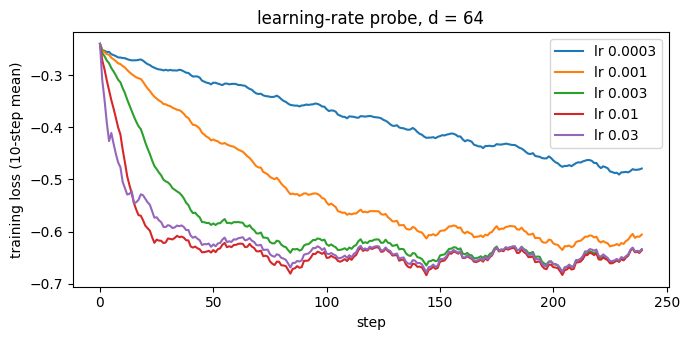

In [12]:
# 4.2 Learning-rate probe (runs once)
choice_path = M2_DIR / "lr_choice.json"
if choice_path.exists():
    choice = json.loads(choice_path.read_text())
    print("using the stored learning-rate choice:", choice_path)
else:
    batch_iter = iter(train_loader)
    probe_batches = []
    for _ in range(PROBE_BATCHES):
        x, y, _ = next(batch_iter)
        probe_batches.append((x.to(DEVICE, torch.bfloat16), y.to(DEVICE)))
    del batch_iter
    curves, speeds = {}, []
    for lr in LR_GRID:
        adapter = LatentAdapter(PROBE_D)
        optimizer = make_optimizer(adapter, lr)
        losses = []
        torch.cuda.synchronize()
        t = time.time()
        for s in tqdm(range(PROBE_STEPS), desc=f"lr {lr:g}", leave=False):
            x, y = probe_batches[s % PROBE_BATCHES]
            parts, _ = train_step(adapter, optimizer, x, y, lr)
            losses.append(parts["loss"])
        torch.cuda.synchronize()
        speeds.append(PROBE_STEPS * BATCH_SIZE / (time.time() - t))
        curves[str(lr)] = losses
        del adapter, optimizer
    del probe_batches
    torch.cuda.empty_cache()
    tail = PROBE_STEPS // 4
    scores = {lr: float(np.mean(c[-tail:])) for lr, c in curves.items()}
    finite = {lr: s for lr, s in scores.items() if np.isfinite(s)}
    best = float(min(finite, key=finite.get))
    choice = {"lr_max": best, "lr_min": best / LR_RATIO, "probe_d": PROBE_D, "probe_steps": PROBE_STEPS,
              "mean_loss_last_quarter": scores, "curves": curves, "gpu_img_per_s": float(np.median(speeds))}
    choice_path.write_text(json.dumps(choice, indent=1))

LR_MAX, LR_MIN = choice["lr_max"], choice["lr_min"]
display(pd.Series(choice["mean_loss_last_quarter"], name="mean loss, last quarter").to_frame().T)
print(f"chosen: LR_MAX = {LR_MAX:g}, LR_MIN = {LR_MIN:g};  GPU speed in latent mode: {choice['gpu_img_per_s']:.0f} img/s")
if LR_MAX in (min(LR_GRID), max(LR_GRID)):
    print("NOTE: the best learning rate is at the edge of LR_GRID; the true optimum may lie outside it")

fig, ax = plt.subplots(figsize=(7, 3.5))
for lr, c in choice["curves"].items():
    ax.plot(pd.Series(c).rolling(10, min_periods=1).mean(), label=f"lr {float(lr):g}")
ax.set_xlabel("step")
ax.set_ylabel("training loss (10-step mean)")
ax.set_title(f"learning-rate probe, d = {PROBE_D}")
ax.legend()
plt.tight_layout()
plt.show()

### 4.3 The d sweep (resumable)

For each d in `D_LIST`: 10 epochs of the M1 recipe in latent form, then the test set. Per run folder (`runs/m2/latent_d<d>_...`): `config.json` (incl. learning rate and W fingerprint), `epoch_XX.pt` and `last.pt` (z, α, optimizer, history; a few KB), `test_predictions.csv`, `results.json`, and `payload.json` (the deployable model: z, α, seeds).

- **Resuming:** run 1.1 → 4.2 (skip 2.4 if you like; 4.2 just reloads the stored choice), then this cell. Finished d are skipped, an interrupted d continues after its last finished epoch with the same data order and learning rate.
- You can stop it at any time (Kernel → Interrupt).
- `CE real / DF / ...` are the training cross-entropies per generator, as in M1.

In [13]:
# 4.3 The d sweep (resumable)
def run_dir_for(d):
    return M2_DIR / f"latent_d{d}_{ARCH}_train-{'-'.join(SHORT[g] for g in TRAIN_GENERATORS)}_seed{SEED}"


def train_latent(d):
    run_dir = run_dir_for(d)
    run_dir.mkdir(parents=True, exist_ok=True)
    adapter = LatentAdapter(d)
    check_config(run_dir, {**COMMON_CONFIG, "d": d, "lr_max": LR_MAX, "lr_min": LR_MIN,
                           "w_fingerprint": w_fingerprint(adapter.W)})
    optimizer = make_optimizer(adapter, LR_MIN)
    history, start_epoch = [], 0
    if (run_dir / "last.pt").exists():
        ckpt = load(run_dir / "last.pt")
        adapter.load_latent(ckpt["latent"])
        optimizer.load_state_dict(ckpt["optimizer"])
        history, start_epoch = ckpt["history"], ckpt["epoch"]
    print(f"\n===== d = {d}: {start_epoch}/{EPOCHS} epochs done =====")

    steps_per_epoch = len(train_loader)
    for epoch in range(start_epoch, EPOCHS):
        train_sampler.set_epoch(epoch)
        model.train()
        sums, n_steps, t0 = defaultdict(float), 0, time.time()
        ce_sum = torch.zeros(len(CATEGORIES), device=DEVICE)
        ce_cnt = torch.zeros(len(CATEGORIES), device=DEVICE)
        for i, (x, y, g) in enumerate(tqdm(train_loader, desc=f"d={d} epoch {epoch + 1}/{EPOCHS}", leave=False)):
            lr = lr_at(epoch * steps_per_epoch + i, steps_per_epoch, LR_MAX, LR_MIN)
            x, y, g = (t.to(DEVICE, non_blocking=True) for t in (x, y, g))
            parts, ce_each = train_step(adapter, optimizer, x, y, lr)
            for k, v in parts.items():
                sums[k] += v
            ce_sum += torch.bincount(g, weights=ce_each, minlength=len(CATEGORIES))
            ce_cnt += torch.bincount(g, minlength=len(CATEGORIES))
            n_steps += 1

        val_table = metrics_table(predict(adapter.theta(), val_df, images["val"], desc="val"))
        row = {"epoch": epoch + 1, "lr (end)": float(lr)}
        row.update({k: v / n_steps for k, v in sums.items()})
        row.update({f"CE {SHORT[c]}": float(ce_sum[k] / ce_cnt[k]) for k, c in enumerate(CATEGORIES) if ce_cnt[k] > 0})
        row.update({"alpha": adapter.alpha.item(), "|z|": adapter.z.norm().item(),
                    "val frame AUC": float(val_table["frame AUC"].iloc[0]),
                    "val video AUC": float(val_table["video AUC"].iloc[0]),
                    "minutes": (time.time() - t0) / 60})
        history.append(row)
        save_atomic(adapter.latent_state(), run_dir / f"epoch_{epoch + 1:02d}.pt")
        save_atomic({"epoch": epoch + 1, "latent": adapter.latent_state(), "optimizer": optimizer.state_dict(),
                     "history": history}, run_dir / "last.pt")
        print(" | ".join(f"{k} {v:.4g}" if isinstance(v, float) else f"{k} {v}" for k, v in row.items()))

    if not (run_dir / "results.json").exists():
        pred = predict(adapter.theta(), test_df, images["test"], desc="test")
        pred.to_csv(run_dir / "test_predictions.csv", index=False)
        table = metrics_table(pred)
        display(table)
        (run_dir / "payload.json").write_text(json.dumps({
            "arch": ARCH, "pretrained": PRETRAINED, "head_init_seed": SEED, "w_seed": W_SEED,
            "w_entries": "N(0, 1/d)", "d": d, "alpha": adapter.alpha.item(), "z": adapter.z.tolist()}))
        (run_dir / "results.json").write_text(json.dumps(
            {"d": d, "test": table.to_dict(orient="records"), "history": history}, indent=1))
    del adapter, optimizer
    torch.cuda.empty_cache()


for d in D_LIST:
    train_latent(d)
print("sweep finished")


===== d = 64: 10/10 epochs done =====

===== d = 256: 10/10 epochs done =====

===== d = 1024: 10/10 epochs done =====

===== d = 16: 10/10 epochs done =====

===== d = 4096: 10/10 epochs done =====
sweep finished


## 5. Evaluation

### 5.1 Full LN tuning (M1) through the same code

M1's checkpoints at epoch 10 (matched to M2's budget) and epoch 20 are scored with M2's evaluation code. Epoch 20 must reproduce M1's own test results (FaceShifter video AUC 88.37); that also confirms that the parameter order used by `write_theta` is right. Stored in `runs/m2/m1_reference.json`.

In [14]:
# 5.1 Full LN tuning (M1) through the same code
def theta_from_m1(epoch):
    state = load(M1_RUN_DIR / f"epoch_{epoch:02d}.pt")
    return torch.cat([state[n].reshape(-1).float() for n in TARGET_NAMES]).to(DEVICE)


ref_path = M2_DIR / "m1_reference.json"
if ref_path.exists():
    m1_ref = json.loads(ref_path.read_text())
else:
    m1_ref = {str(e): metrics_table(predict(theta_from_m1(e), test_df, images["test"], desc=f"M1 epoch {e}")
                                    ).to_dict(orient="records") for e in (10, 20)}
    ref_path.write_text(json.dumps(m1_ref, indent=1))

for e in ("10", "20"):
    print(f"\n=== M1 full LN tuning, epoch {e} ===")
    display(pd.DataFrame(m1_ref[e]))
fsh_20 = pd.DataFrame(m1_ref["20"]).set_index("test set").loc["FaceShifter", "video AUC"]
print(f"epoch 20 FaceShifter video AUC: {fsh_20:.2f} (M1 notebook: 88.37) ->",
      "MATCH" if abs(fsh_20 - 88.37) < 0.3 else "MISMATCH: send the notebook before going on")


=== M1 full LN tuning, epoch 10 ===


,test set,status,frame AUC,video AUC,video acc @0.5,real / fake videos
0,seen combined (DF+F2F+FS+NT),seen,95.66,97.60,93.14,140 / 560
1,Deepfakes,seen,98.17,99.22,95.36,140 / 140
2,Face2Face,seen,96.06,98.09,93.21,140 / 140
3,FaceSwap,seen,98.15,99.20,95.71,140 / 140
4,NeuralTextures,seen,90.25,93.88,87.86,140 / 140
5,FaceShifter,UNSEEN,81.20,88.19,73.21,140 / 140



=== M1 full LN tuning, epoch 20 ===


,test set,status,frame AUC,video AUC,video acc @0.5,real / fake videos
0,seen combined (DF+F2F+FS+NT),seen,96.36,98.04,93.57,140 / 560
1,Deepfakes,seen,98.40,99.39,95.71,140 / 140
2,Face2Face,seen,96.78,98.40,93.21,140 / 140
3,FaceSwap,seen,98.54,99.38,95.71,140 / 140
4,NeuralTextures,seen,91.71,94.98,88.57,140 / 140
5,FaceShifter,UNSEEN,81.98,88.37,73.57,140 / 140


epoch 20 FaceShifter video AUC: 88.37 (M1 notebook: 88.37) -> MATCH


### 5.2 AUC as a function of d

One row per model: seen generators combined, each generator, and FaceShifter (unseen) at video and frame level. The figure shows video AUC against d, with full LN tuning (M1, epoch 10 and 20) as horizontal lines. What we look for: the smallest d whose FaceShifter AUC is within about 1 point of full LN tuning, and whether d = 64 is enough.

,d,trainable,seen video AUC,seen frame AUC,DF video AUC,F2F video AUC,FS video AUC,NT video AUC,FSh video AUC,FSh frame AUC
model,,,,,,,,,,
"M1 full LN tuning, epoch 10",104450,104450,97.60,95.66,99.22,98.09,99.20,93.88,88.19,81.20
"M1 full LN tuning, epoch 20",104450,104450,98.04,96.36,99.39,98.40,99.38,94.98,88.37,81.98
latent d = 16,16,17,50.11,49.98,51.44,48.08,48.45,52.47,58.29,56.95
latent d = 64,64,65,46.56,47.11,43.08,52.51,41.25,49.40,55.56,53.49
latent d = 256,256,257,55.97,53.59,61.24,54.76,56.52,51.36,48.96,49.44
latent d = 1024,1024,1025,72.63,68.50,88.72,68.43,74.73,58.63,67.58,63.83
latent d = 4096,4096,4097,96.80,93.90,99.41,97.57,99.47,90.76,78.72,73.93


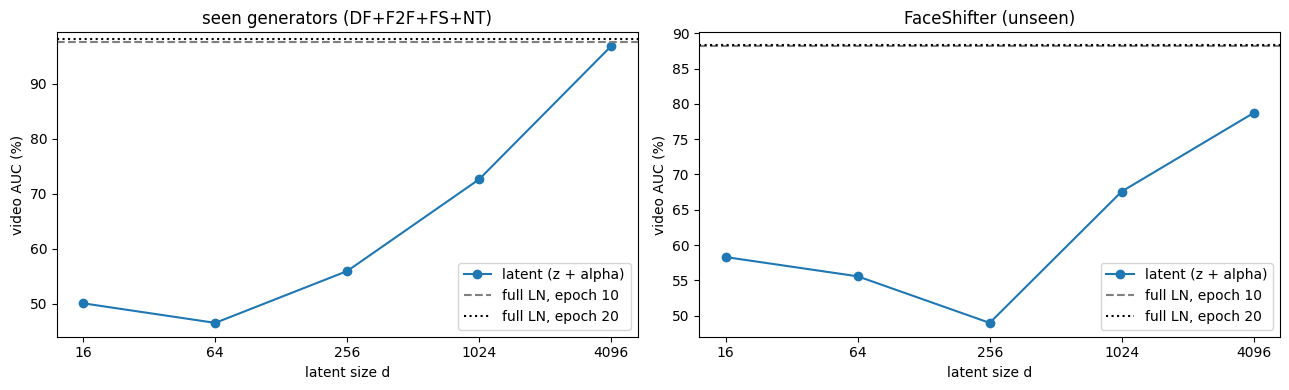

In [15]:
# 5.2 AUC as a function of d
def summary_row(model_name, d, trainable, records):
    t = pd.DataFrame(records).set_index("test set")
    row = {"model": model_name, "d": d, "trainable": trainable,
           "seen video AUC": t.iloc[0]["video AUC"], "seen frame AUC": t.iloc[0]["frame AUC"]}
    row.update({f"{SHORT[g]} video AUC": t.loc[g, "video AUC"] for g in ALL_GENERATORS})
    row["FSh frame AUC"] = t.loc["FaceShifter", "frame AUC"]
    return row


rows = [summary_row("M1 full LN tuning, epoch 10", P, P, m1_ref["10"]),
        summary_row("M1 full LN tuning, epoch 20", P, P, m1_ref["20"])]
latent_results = {}
for d in sorted(D_LIST):
    path = run_dir_for(d) / "results.json"
    if path.exists():
        latent_results[d] = json.loads(path.read_text())
        rows.append(summary_row(f"latent d = {d}", d, d + 1, latent_results[d]["test"]))
    else:
        print(f"d = {d}: not finished yet")
sweep = pd.DataFrame(rows).set_index("model")
display(sweep.round(2))
(M2_DIR / "sweep_summary.csv").write_text(sweep.to_csv())

if latent_results:
    ds = sorted(latent_results)
    lat = sweep.loc[[f"latent d = {d}" for d in ds]]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, col, title in [(axes[0], "seen video AUC", "seen generators (DF+F2F+FS+NT)"),
                           (axes[1], "FSh video AUC", "FaceShifter (unseen)")]:
        ax.plot(ds, lat[col], marker="o", label="latent (z + alpha)")
        ax.axhline(sweep.loc["M1 full LN tuning, epoch 10", col], color="gray", linestyle="--", label="full LN, epoch 10")
        ax.axhline(sweep.loc["M1 full LN tuning, epoch 20", col], color="black", linestyle=":", label="full LN, epoch 20")
        ax.set_xscale("log", base=2)
        ax.set_xticks(ds, [str(d) for d in ds])
        ax.set_xlabel("latent size d")
        ax.set_ylabel("video AUC (%)")
        ax.set_title(title)
        ax.legend()
    plt.tight_layout()
    plt.show()

### 5.3 Training curves

Left: FF++ val video AUC per epoch for every d (8 frames per video) and for M1 (32 frames per video, first 10 epochs). Middle: training loss. Right: final training cross-entropy per generator against d; the spread between generators is the dominance pattern E1 (M3) will measure, and here we see whether the small latent keeps or changes it.

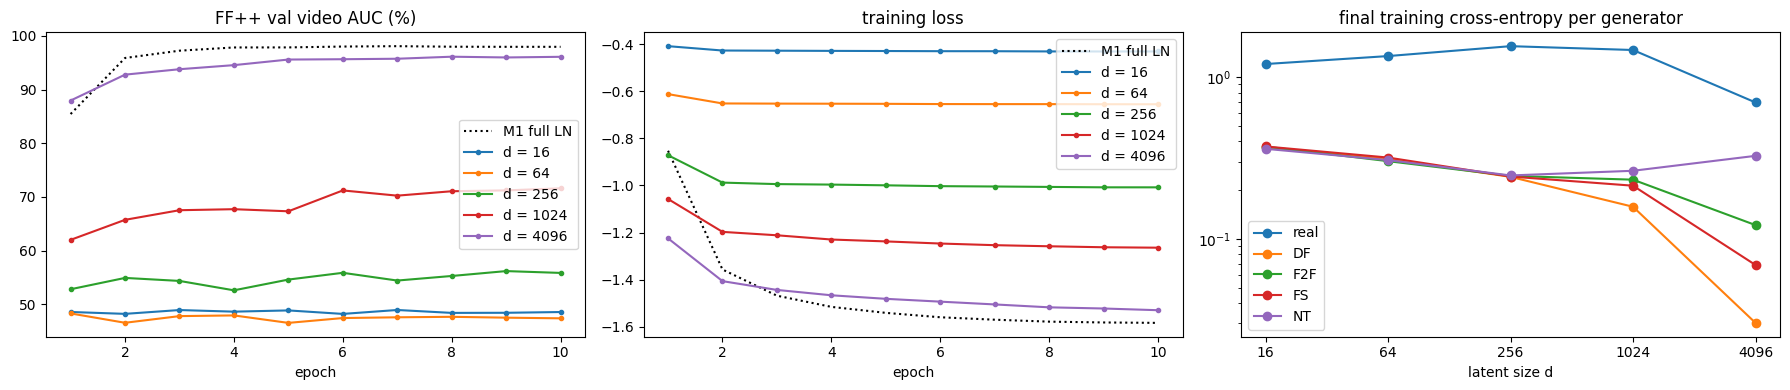

final training cross-entropy per generator:


,CE real,CE DF,CE F2F,CE FS,CE NT
16,1.2004,0.3667,0.3712,0.3717,0.3596
64,1.3442,0.3122,0.3017,0.3175,0.3063
256,1.5476,0.2413,0.2446,0.2424,0.2462
1024,1.4655,0.1577,0.2318,0.2128,0.2631
4096,0.6951,0.0303,0.1215,0.0689,0.3253
"M1 full LN, epoch 10",0.4777,0.0311,0.1069,0.0605,0.3013


In [16]:
# 5.3 Training curves
m1_hist = pd.DataFrame(load(M1_RUN_DIR / "last.pt")["history"]).iloc[:EPOCHS]
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(m1_hist.epoch, m1_hist["val video AUC"], color="black", linestyle=":", label="M1 full LN")
axes[1].plot(m1_hist.epoch, m1_hist["loss"], color="black", linestyle=":", label="M1 full LN")
for d, res in sorted(latent_results.items()):
    h = pd.DataFrame(res["history"])
    axes[0].plot(h.epoch, h["val video AUC"], marker=".", label=f"d = {d}")
    axes[1].plot(h.epoch, h["loss"], marker=".", label=f"d = {d}")
axes[0].set_title("FF++ val video AUC (%)")
axes[1].set_title("training loss")
for ax in axes[:2]:
    ax.set_xlabel("epoch")
    ax.legend()

if latent_results:
    ce_cols = [f"CE {SHORT[c]}" for c in CATEGORIES if f"CE {SHORT[c]}" in m1_hist.columns]
    final_ce = pd.DataFrame({d: pd.DataFrame(r["history"]).iloc[-1][ce_cols] for d, r in sorted(latent_results.items())}).T
    for c in ce_cols:
        axes[2].plot(final_ce.index, final_ce[c], marker="o", label=c[3:])
    axes[2].set_xscale("log", base=2)
    axes[2].set_xticks(list(final_ce.index), [str(d) for d in final_ce.index])
    axes[2].set_yscale("log")
    axes[2].set_xlabel("latent size d")
    axes[2].set_title("final training cross-entropy per generator")
    axes[2].legend()
    final_ce.loc["M1 full LN, epoch 10"] = m1_hist.iloc[-1][ce_cols]
    plt.tight_layout()
    plt.show()
    print("final training cross-entropy per generator:")
    display(final_ce.astype(float).round(4))
else:
    plt.show()

## 6. Send results back

1. Save this notebook (Ctrl+S) with its outputs.
2. From the repository folder on C-DAC:

```bash
git pull
git add M2.ipynb
git commit -m "M2 run outputs"
git push
```

When git asks for a password, paste your GitHub token. Do not put the token in this notebook or any file, and do not send it to me. Only `M2.ipynb` is committed; runs stay in `runs/m2/` on C-DAC.

**Suggested order:** run 1.1 → 4.2 first (about 30–45 min including loading the crops into RAM) and **push once** so I can check the loading speed (2.4), the latent checks (3.3) and the chosen learning rate (4.2) before hours of training. Then run 4.3 (hours, resumable across sessions), then section 5. If 2.4 says the bottleneck is data loading, push right away: I'll move the augmentations to the GPU first.

**What I need from the outputs:** environment (1.2), RAM loading (2.2), loading speed (2.4), checks (3.1, 3.3), parameter report (3.4), the probe (4.2), the epoch lines of 4.3, and all of section 5.

**What M2 hands to the next milestones:** the latent parameterization (`LatentAdapter`, `write_theta`) that GBLA builds on; the smallest d that keeps full-LN accuracy; and the pooled latent solution at d = 64 (`runs/m2/latent_d64_.../epoch_10.pt`) whose per-generator curvature E1 measures in M3.